# Gradient Boosting
Reprise du pipeline `GBC` de `model/final_notebook_cleaning_column_transformer.ipynb`.

Structure : pipeline → cross-validation → fit sur tout le train → soumission.
Le nettoyage vient de `src/titanic/features.py` (partagé par tous les modèles).

In [1]:
import warnings

from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (à importer avant IterativeImputer)
from sklearn.impute import IterativeImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from titanic.features import load_data, make_column_transformer, save_submission

warnings.filterwarnings("ignore")
X, y, test = load_data()
X.shape, test.shape

((891, 11), (418, 11))

## Pipeline
Nettoyage (importé) → mise à l'échelle → imputation des NaN → modèle.
Rien n'est entraîné ici : c'est la « recette ».

In [2]:
pipe = Pipeline([
    ("prep", make_column_transformer("title")),
    ("scaler", StandardScaler()),
    ("imputer", IterativeImputer(estimator=Ridge(), max_iter=1000, random_state=0, tol=1e-3)),
    ("model", GradientBoostingClassifier(random_state=0)),
])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('drop_id', ...), ('cabin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, d

## Cross-validation
25 notes (5 découpages × 5 répétitions). La CV entraîne ses propres copies du pipeline ; `pipe` lui-même reste non entraîné.

In [3]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)
scores = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
print(f"CV : {scores.mean():.4f} ± {scores.std():.4f}  (min {scores.min():.3f}, max {scores.max():.3f})")

CV : 0.8310 ± 0.0229  (min 0.787, max 0.865)


## Matrice de confusion
Quel type d'erreur fait le modèle : rate-t-il des survivants (FN) ou en invente-t-il (FP) ?

Prédictions **hors-fold** (`cross_val_predict`) : chaque passager est prédit par un modèle qui ne l'a pas vu à l'entraînement.
Prédire sur le train après `fit` donnerait ~91 % de bonnes réponses, un chiffre trompeur.

Lecture : lignes = réalité, colonnes = prédiction, ordre 0 (mort) puis 1 (survivant) → `[[VN, FP], [FN, VP]]`.

VN=486  FP=63  FN=91  VP=251
accuracy 0.827  précision 0.799  rappel 0.734  F1 0.765
survivants prédits 35.2% (réels 38.4%)


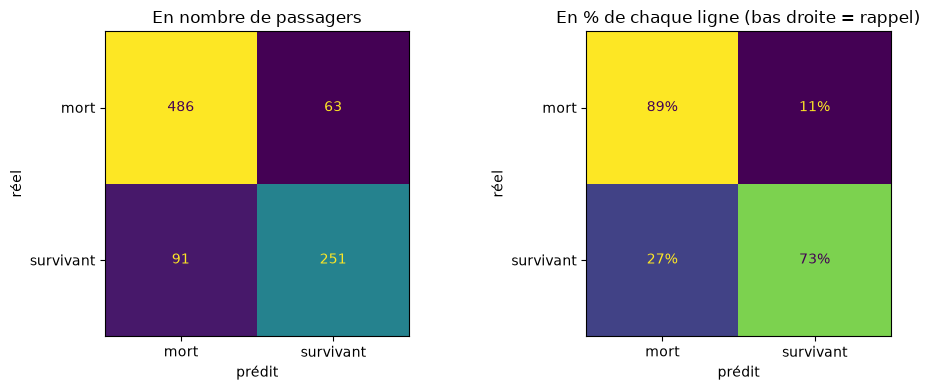

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict

oof = cross_val_predict(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), n_jobs=-1)

cm = confusion_matrix(y, oof)
(vn, fp), (fn, vp) = cm
print(f"VN={vn}  FP={fp}  FN={fn}  VP={vp}")
print(f"accuracy {accuracy_score(y, oof):.3f}  précision {precision_score(y, oof):.3f}  "
      f"rappel {recall_score(y, oof):.3f}  F1 {f1_score(y, oof):.3f}")
print(f"survivants prédits {oof.mean():.1%} (réels {y.mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(cm, display_labels=["mort", "survivant"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("En nombre de passagers")
ConfusionMatrixDisplay(confusion_matrix(y, oof, normalize="true"), display_labels=["mort", "survivant"]).plot(
    ax=axes[1], colorbar=False, values_format=".0%")
axes[1].set_title("En % de chaque ligne (bas droite = rappel)")
for ax in axes:
    ax.set_xlabel("prédit"); ax.set_ylabel("réel")
plt.tight_layout()
plt.show()

In [5]:
# Où se concentrent les erreurs ? (par sexe et classe)
d = pd.DataFrame({"Sex": X["Sex"], "Pclass": X["Pclass"], "y": y, "pred": oof})
d["FN"] = (d.y == 1) & (d.pred == 0)
d["FP"] = (d.y == 0) & (d.pred == 1)
groupes = d.groupby(["Sex", "Pclass"]).agg(
    n=("y", "size"), survie_reelle=("y", "mean"), survie_predite=("pred", "mean"),
    FN=("FN", "sum"), FP=("FP", "sum"))
groupes["erreurs"] = groupes.FN + groupes.FP
groupes.style.format({"survie_reelle": "{:.0%}", "survie_predite": "{:.0%}"}).background_gradient(subset="erreurs", cmap="Reds")

## Soumission
On entraîne une seule fois sur les 891 lignes, puis on prédit le test Kaggle.

In [6]:
pipe.fit(X, y)
ypred = pipe.predict(test)
path = save_submission(test, ypred, "gbc")
print(f"{path} : {len(ypred)} prédictions, {ypred.mean():.1%} de survivants prédits")

/home/lucas/personal/TitanicMachineLearningFromDisaster/submissions/gbc.csv : 418 prédictions, 36.6% de survivants prédits
